In [315]:
# Initialize Otter
import otter
grader = otter.Notebook("week3.ipynb")

# HW3: Planning A Route
#### CS-31: Foundations for Artificial Intelligence
*Point breakdown: 20 autograded · 70 manually graded · 10 collaboration statement = 100*


### AI Use  Disclosure
- The code for the interactive search visualization in `search_viz.py` was generated with a combination of Claude, DeepSeek, and my own edits. The rationale behind this was that after extensive online search, I could not find an existing Python library that demonstrated a step-by-step visualization of A* that would allow you to make the modifications and explorations I wanted you to make. Finally, as this is only a pedagogical visualization, and I have implemented these algorithms before it is low-enough stakes where I am comfortable having AI generate it.
- The code to generate the campus graph visualization was also generated with assistance from Claude.
- The `campus_graph.json`, `accessibility_needs.csv`, and `no_accessibility_needs.csv` files are synthetic data that was constructed with the help of Claude/DeepSeek. I wanted to give you a moderately complex problem that wasn't a "toy problem", but still wanted for it to demonstrate realistic results.
- All other code was hand authored by me. In addition, I also hand wrote the code to run the experiments I ask you to run, to verify that it is feasible.
- All prose and text was written by me.

*You are allowed to work in groups for the lab. You must write anything that will be turned in -- all code and all written solutions -- on your own. You must list all people and resources that you interacted with in the Collaboration Statement below. See [course policies](https://www.cs.tufts.edu/comp/31/policy.html) for more information.*

--

In this assignment, you'll explore how **planning problems** can be solved by **searching** through a **state space**. You'll compare Breadth-First Search, A*, and Greedy Search on grid maps, and then apply shortest path algorithms on a simulated campus map to do data analysis.

For now, we only consider deterministic offline planning. **Deterministic** planning means that there is no randomness, and the agent knows exactly what each action does and how it changes the current state. **Offline** planning means that the state of the world doesn't change while the agent is forming its plan, and thus can't react if the world changes between forming the plan and executing the plan.

The power of the planning formalism is that if you can represent your problem as a set of states, and a set of actions that one can perform in these states that can take you to other states - we can solve many seemingly different types of problems via **search algorithms**. Some examples are:

- Finding the shortest path from one corner of the room to another while avoiding obstacles
- Finding the [best sequence of routers](https://en.wikipedia.org/wiki/Routing) to send data across a network while minimizing travel time

### **Table of Contents**

1) Search Algorithms on Grid Maps
2) Graphs and a Hilly Campus
3) Collaboration Statement

## **1. Search Algorithms on Grid Maps**

Since AI applications vary a lot with problem types, or are hard to prove mathematically, developers sometimes simulate the performance of their algorithms in synthetic environments.

### **1.0 Controlling Randomness**

Oftentimes, we want to work with random data and algorithms that have random components. However, we also want our experiments to be repeatable! Turns out, the numbers that computers generate aren't *really* random. They are [*pseudo-random*](https://en.wikipedia.org/wiki/Pseudorandomness), which means that while they are deterministically generated, they are statistically indistinguishable from a *true* random sequence. This means that we can control this randomness (and if you're a smart hacker, exploit algorithms that rely on these so called "random" behaviors).

Notice how for this chunk of code, we get two random sequences of numbers.

In [316]:
import random

for i in range(4):
    print(random.uniform(1,10))

print("----")

for i in range(4):
    print(random.uniform(1,10))

7.0902953868062015
9.029616109343609
1.7824494936647453
4.797296377167434
----
1.268174974942633
2.9677417732324303
5.548197592930261
1.2388237271547726


We can control the randomness via a *seed* - a number to start the random number generation. If you don't specify a seed, Python will just pull from your system clock, which is "random enough". However, if you reset the seed to the same number, it will generate the same sequence of random numbers! This is how we can verify and test algorithms that have some component of randomness - and makes our tests **reproducable**, even if there's randomness involved!

In [317]:
# Set our seed and generate some numbers...
random.seed(42)
for i in range(4):
    print(random.uniform(1,10))

print("----")

# Reset the generator...
random.seed(32)
for i in range(4):
    print(random.uniform(1,10))

print("----")

# Same as the first 42 sequence!
random.seed(42)
for i in range(4):
    print(random.uniform(1,10))

6.754841186120954
1.2250967970040025
3.4752638653220735
3.008896643339405
----
1.6967960546797372
2.922551105184895
3.7281550339250686
9.101923146398027
----
6.754841186120954
1.2250967970040025
3.4752638653220735
3.008896643339405


In this lab, we will work with randomly generated maps, but with a given starting seed.

### **1.1 Obstacle Course Maps**

In this part of the assignment, you'll be exploring how BFS, A*, and Greedy Search compare in terms of performance and solution quality in a navigation problem on an obstacle course.

The function `generate_object_map(n, density, seed)` creates an `n`x`n` map that randomly overlays rectangles of varying dimensions across the empty map proportional to the `density` parameter.

- A low density such as `0.1` leaves a lot of wide open space, like a room with a few objects scattered about.
- A higher density such as `0.6` creates a cave or dungeon-like layout.

In addition, we add a random `seed` to control the randomness.

In [318]:
from search_viz import *

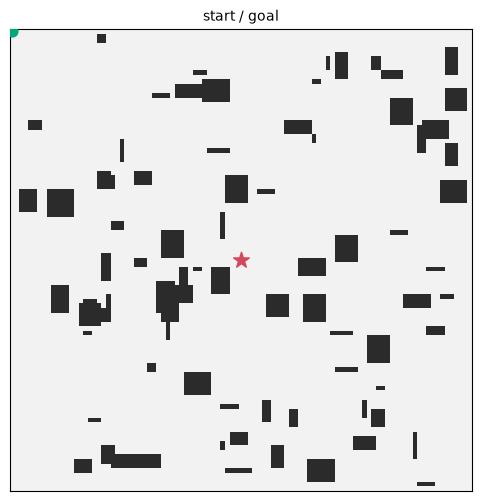

In [319]:
# Create a sparse map
sparse_course = generate_object_map(101, density=0.1, seed=15)
stepper(sparse_course)

A higher density such as `0.6` creates a cave or dungeon-like layout.

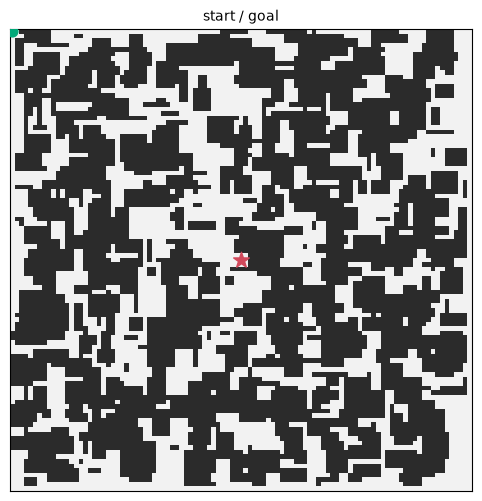

In [320]:
dense_course = generate_object_map(101, density=0.6, seed=15)
stepper(dense_course)

Any higher densities (e.g. `0.9`) may leave the map unsolvable, which is accounted for.

In [321]:
# Uncomment the following line and try and generate a map. You'll see that it fails.
# generate_object_map(101, density=0.9, seed=15)

### **1.2 Setting Up The Map**

Maps are of size $n \times n$, where we can set $n$. Our initial state is always $(0,0)$ (the top-left corner). For the object maps from Section 1.1, our goal state is the center of the map, $((n-1)//2, (n-1)//2)$.

For the following few examples, let's work with this map.

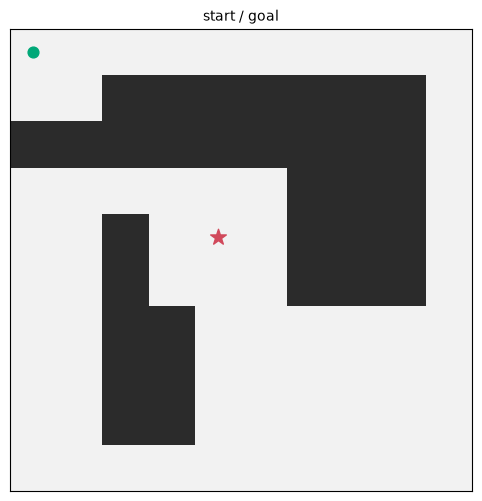

In [322]:
demo_map = generate_object_map(10, density=0.4, seed=31)
stepper(demo_map)

At any given square, the agent's actions are that it can move up, down, left, or right (not diagonally). However, it cannot move through walls, so if an action would move it into a wall, that action is not available.

The `neighbors(grid, state)` function takes in the map as well as the current *state*, and provides a list of free neighbors (e.g. the possible actions the agent could take). The `state` is represented as a tuple of `(row, col)`.

In [323]:
# We see that the available free neighbors at (0,0) for the above map 
# are either 1) move one unit down or 2) move one unit right.
list(neighbors(demo_map, (0,0)))

[(1, 0), (0, 1)]

In [324]:
# We see that the available free neighbors at (0,2) for the above map 
# are 1) move one unit right or 2) move one unit left
print("Neighbors at (row: 0, col: 2)")
list(neighbors(demo_map, (0,2)))

Neighbors at (row: 0, col: 2)


[(0, 3), (0, 1)]

Finally, we'll be providing you with the functions `bfs`, `astar` and `greedy`, which run their respective search algorithms on a given grid, and return an object that showcases a variety of information about the run.

- `expanded` gives the number of nodes that were expanded throughout the search process
- `path_cost` gives the total cost of the path (i.e. the number of nodes in the path, since this is an unweighted graph)
- `path` gives the actual path from the initial state to the goal state

In [325]:
bfs_search_result = bfs(demo_map)
print(f"Number of nodes expanded: {bfs_search_result.expanded}")
print(f"Final path cost: {bfs_search_result.path_cost}")
print(f"Final path: {bfs_search_result.path}")

Number of nodes expanded: 45
Final path cost: 22
Final path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (6, 8), (6, 7), (6, 6), (6, 5), (5, 5), (4, 5), (4, 4)]


Finally, we can add results of the search to our stepper, which will provide an interactive widget where you can see the explored and frontier set, as well as the final path.

- Explored nodes are in a light grey/blueish color
- Nodes on the frontier range from bright "hot" yellow to a deep "cool" purple.
    - Yellow and "hot" colors represent the node with the *lowest* cost on the frontier
    - Purple and "cool" colors represent the node with the *highest* cost on the frontier

You can run the animation below to see how BFS explores on this map.

- Click on the *Play* button to run the entire animation
- You can also step through the animation by pressing the *Previous* and *Next step* buttons

`stepper` has a few optional keyword arguments
- `display` can either be `"f"`, `"g"`, or `"h"`. This controls what value is colored in and shown for the nodes on the frontier. Remember that "g" is the current cost of the path, "h" is the heuristic cost of the node, and "f" is g+h.
- `show_value` triggers whether we show the actual number of the value set in `display`
- `show_parent` determines whether to draw the arrows at each node that point back to the parent. These are used to reconstruct the shortest path from each node to the goal.

Note: When running the stepper you might get an error that says:
-  `Could not render content for 'application/vnd.jupyter.widget-view+json'
Usually restarting your notebook fixes this.

In [326]:
# Finally, we can pass in the search result to the stepper
# and view the search process in action
stepper(
        demo_map, 
        bfs_search_result, 
        display="g", # What value to display, activates the color
        show_value=True, # Boolean to actually show the numerical value of what is flagged in `display`
        show_parent=True # Whether to draw arrows at each node pointing back to the parent. To reconstruct path
)  

#### **Exercise 1.1 (Written): Breadth-First Search and the Frontier.** **(5 pts)**

On step 19, we see that the three nodes on the frontier have a path cost of 16, 17, and 17. Why does breadth first search choose the node with the value of 16?

<!-- BEGIN QUESTION -->
Because breadth first search will step through all the options before continuing to the next level and the node at 16 is the first node that has options of going to the left. The node at 16 also has less heuristic and current cost than the other nodes.


<!-- END QUESTION -->

### **1.3 Search with a Zero Heuristic**

For the following examples, we'll use a map with `n=26`, `density=0.6`, and `seed=11`.

In [327]:
test_map = generate_object_map(26, density=0.6, seed=11)

In order to run a greedy search, we first need a heuristic function that can prioritize different states to choose. We can pass in a custom heuristic function to both the `greedy` and `astar` functions.

A heuristic function takes in two states `(a, b)` and returns the estimated path distance between them. We only provide you with a dummy heuristic that returns 0 for all pairs of states.

In [328]:
def null_heuristic(a,b):
    return 0

In [329]:
greedy_null_search_result = greedy(test_map, null_heuristic)
print(f"Number of nodes expanded: {greedy_null_search_result.expanded}")
print(f"Final path cost: {greedy_null_search_result.path_cost}")

Number of nodes expanded: 98
Final path cost: 24


In [330]:
astar_null_test_result = astar(test_map, null_heuristic)
print(f"Number of nodes expanded: {astar_null_test_result.expanded}")
print(f"Final path cost: {astar_null_test_result.path_cost}")

Number of nodes expanded: 98
Final path cost: 24


In [331]:
stepper(test_map ,
        bfs_search_result, 
        display="f", 
        show_value=True, 
        show_parent=True)

#### **Exercise 1.2 (Written): When Zero Heuristic Reduces to BFS.** **(5 pts)**

You will notice that both of these results are exactly the same as the BFS result. This is not a coincidence.

**For maps with unit cost (unweighted), why are both greedy search and A\* with the heuristic value of always zero identical to BFS?**

As a reminder:
- BFS search only expands relevant to $g(n)$
- Greedy search only expands relevant to $h(n)$
- A* search expands relevant to $f(n) = g(n) + h(n)$

<!-- BEGIN QUESTION -->

A* and BFS are the same because as far as the algorith is concerned, there is no optimal path here unless it runs into a dead end which means the heuristic cost will be unknown. Therefore, For both of these algorithms, it is $f(n) = g(n)$. For greedy algorithm, it is the same as BFS in this case is because it explores the path with the least distance. This is similar to BFS since it also explores the path with the least distance first since they are higher on the decision tree branch.


<!-- END QUESTION -->

### **1.4 The Manhattan Heuristic**

The [**Manhattan distance**](https://en.wikipedia.org/wiki/Taxicab_geometry) is a distance metric. It's a simpler version of the more familiar [Euclidean distance](https://en.wikipedia.org/wiki/Euclidean_distance), which you are most likely familiar with as the way to calculate the straight line distance between two points (aka, the Pythagorean theorem). 

The Manhattan distance is defined as the sum of the absolute differences of each matching coordinate. Since our agent cannot move diagonally, the Manhattan distance gives the cost that it would take to get from point *a* to point *b* (assuming zero obstacles or "as the crow flies").

#### **Exercise 1.3: The Manhattan Distance.**

Implement the `manhattan_distance(a, b)` function. You should test your function against the provided cases.

In [332]:
def manhattan_distance(a, b) -> int:
    return abs(a[0]-b[0]) + abs(a[1]-b[1])

In [333]:
grader.check("q_manhattan_distance")

q_manhattan_distance results: All test cases passed!

### **1.5 Comparing Results on a Single Map**

On `test_map`, compare the number of expanded nodes (`result.expanded`) and the final path cost (`result.path_cost`) for:
- BFS 
- Greedy with the Manhattan distance heuristic
- A* with the Manhattan distance heuristic

In addition, visually inspect the planning frontier expansion process by using `stepper(grid, result, display="f", show_value=True)`. Each frontier node is annotated with its $f = g + h$ value, the cost that determines the expansion order.

Use these pieces of data to compare the outputs of the algorithms both in memory used (e.g. nodes expanded) and solution path quality.

In [334]:
bfs_search_result = bfs(test_map)
print("BFS: ")
print(f"Number of nodes expanded: {bfs_search_result.expanded}")
print(f"Final path cost: {bfs_search_result.path_cost}")

BFS: 
Number of nodes expanded: 98
Final path cost: 24


In [335]:

greedy_manhattan_search_result = greedy(test_map, 
                                        manhattan_distance
                                )

print("Greedy Manhattan: ")
print(f"Number of nodes expanded: {greedy_manhattan_search_result.expanded}")
print(f"Final path cost: {greedy_manhattan_search_result.path_cost}")



Greedy Manhattan: 
Number of nodes expanded: 53
Final path cost: 28


In [336]:
# Notice the "tie_break" parameter
# If two nodes have the same "f" value, this is how we break ties
# You'll explore this more in a second

astar_manhattan_search_result = astar(test_map, 
                                      manhattan_distance, 
                                      tie_break="order" # Break ties by their h value
                                      )

print("A* Manhattan: ")
print(f"Number of nodes expanded: {astar_manhattan_search_result.expanded}")
print(f"Final path cost: {astar_manhattan_search_result.path_cost}")

A* Manhattan: 
Number of nodes expanded: 65
Final path cost: 24


In [337]:
stepper(test_map ,
        astar_manhattan_search_result, # <-- Swap this!
        display="g", 
        show_value=True,
        show_parent=True)

#### **Exercise 1.4 (Written): Comparing Algorithms** **(10 pts)**

Visually compare the outputs of A*, BFS, and Greedy Search for `test_map`. Visualize the explored frontier and the final path for each search result by using the `display` keyword for the `"f"`, `"g"`, and `"h"` values.

- Where in the map does the greedy algorithm introduce the inefficiency that leads to a suboptimal path? 
    - What feature of the map makes this happen? 
    - How does it compare to BFS's explored frontier and solution? 
    - How does A* balance these?
- You'll notice that when running A*, there are two possible nodes with value 24 that we can explore. Behind the scenes, there is a tiebreaker function that when faced with two nodes of equal $f(n)$ value, chooses the one with the lowest $h(n)$ value. 
    - Predict how A* would perform in this case if this tiebreaker weren't present and instead we always explored equal-value $f(n)$ nodes by the order they were put on the queue. 
    - Then, change `tie_break` to `"order"` to test your result.

<!-- BEGIN QUESTION -->

- The greedy algorithm introduces some inefficiency at the beginning after it explored the first path which led to a dead end. This resulted in a suboptimal path because greedy search prioritizes steps with the least distance and searches one path at a time. So instead of going back to the beginning, it went back to the last step that has multiple options which ultimately led to producing a suboptimal path. On the other hand, A* algorithm searches all the possible path equally and went back furthur before determining a path with the least cost so it avoided going back to a potentially suboptimal route.

- if it were not for the tie breaker function, A* would go on to explore more nodes such as the nodes with value of 23 so the number of expanded nodes would be higher. 

<!-- END QUESTION -->

### **1.6 Scaling Experiments: Object Maps**

As you may have guessed, I chose that specific map and seed because it nicely illustrates the differences between the search algorithms. We'd like to see how this changes if we sample across multiple maps of different sizes.

In this section **You are going to run an experiment comparing A\*, Greedy, and BFS on different map sizes and random seeds.**

Your independent variables are:

- Size of map
- Random seeds
- A*/Greedy/BFS

We will keep fixed the `DENSITY` at 0.3.

You will run a test for each combination of (map_size x random_seed x algorithm). This means you're running 5\*5\*3 = 75 map solves all together.

Then, create the following two plots:

- **Average Number of Node Expansions vs. Map Size per Algorithm**
    - For each (algorithm x map_size), you should average the number of nodes expanded across the 5 trials.
    - This should be a line plot with three lines, where each line is a different algorithm.
- **Average Greedy/Optimal Path Cost Ratio vs. Map Size**
    - For each (algorithm x map_size), you should average the path costs across the 5 trials.
    - Calculate the ratio of the average cost of the greedy path compared to the average optimal path cost (as given by BFS or A*). This should be a number ≥ 1 (greedy can never beat the optimal path, but it may tie).

**Make sure that you label your figures and your axes.**

#### **Exercise 1.5.1 (Written): Predict Scaling on Object Maps.** **(10 pts)**

Answer the first two bullets *before* you run the experiment.

- What do you predict the Average Number of Node Expansions vs. Map Size per Algorithm graph will look like?
    - Make a prediction for each algorithm on how it will grow.
- What do you predict the Average Greedy/Optimal Path Cost Ratio vs. Map Size graph will look like?

<!-- BEGIN QUESTION -->
- I think as the size of the map increases number of node expansion will increase as well. For BFS, it will definitely increase because there are more paths that could be explored. For Greedy algorithm, the node expansion will increase because there are potentially more options with similar costs that it will need to explore. Similarly, the node expansion of A* algorithm will also likely increase because there could be more options with similar graph and heuristic costs that cannot be differentiated by a tiebreaker.

- I predict taht the ratio for greedy vs. map size is 1.2. I think the graph will rise as the map size increases because greedy replies on heuristic estimate of the distance so as the map grows it has more potential to run into dead ends resulting in more suboptimal routes.


Now, write code to run the experiment. It might help you to use Python's [statistics](https://docs.python.org/3/library/statistics.html) package for some of the results. Here are some starting definitions.

In [338]:
import statistics

DENSITY = 0.3
SIZES = [50, 100, 500, 800, 1000]
RANDOM_SEEDS = [1, 2, 3, 4 , 5]

In [339]:
# Scratch Space
# Feel free to add more cells directly below this.

In [340]:
# Average Number of Node Expansions vs. Map Size per Algorithm
node_y = []
path_y = []

for size in SIZES:
    for seed in RANDOM_SEEDS:
        map_grid = generate_object_map(
            size,
            density=DENSITY,
            seed=seed
        )

        astar_result = astar(
            map_grid,
            manhattan_distance,
            tie_break="h"
        )
        node_y.append({
            "algorithm": "astar",
            "map_size": size,
            "seed": seed,
            "expanded_node": astar_result.expanded,
        })
        path_y.append({
            "algorithm": "astar",
            "map_size": size,
            "seed": seed,
            "path": astar_result.path_cost,
        })

        greedy_result = greedy(
            map_grid, 
            manhattan_distance)
        node_y.append({
            "algorithm": "greedy",
            "map_size": size,
            "seed": seed,
            "expanded_node": greedy_result.expanded,
        })
        path_y.append({
            "algorithm": "greedy",
            "map_size": size,
            "seed": seed,
            "path": greedy_result.path_cost,
        })
        bfs_result = bfs(map_grid)
        node_y.append({
            "algorithm": "bfs",
            "map_size": size,
            "seed": seed,
            "expanded_node": bfs_result.expanded,
        })
        path_y.append({
            "algorithm": "bfs",
            "map_size": size,
            "seed": seed,
            "path": bfs_result.path_cost,
        })

print(f"Collected {len(node_y)} results")

Collected 75 results


In [341]:
print(node_y)

[{'algorithm': 'astar', 'map_size': 50, 'seed': 1, 'expanded_node': 70}, {'algorithm': 'greedy', 'map_size': 50, 'seed': 1, 'expanded_node': 70}, {'algorithm': 'bfs', 'map_size': 50, 'seed': 1, 'expanded_node': 723}, {'algorithm': 'astar', 'map_size': 50, 'seed': 2, 'expanded_node': 265}, {'algorithm': 'greedy', 'map_size': 50, 'seed': 2, 'expanded_node': 68}, {'algorithm': 'bfs', 'map_size': 50, 'seed': 2, 'expanded_node': 640}, {'algorithm': 'astar', 'map_size': 50, 'seed': 3, 'expanded_node': 142}, {'algorithm': 'greedy', 'map_size': 50, 'seed': 3, 'expanded_node': 74}, {'algorithm': 'bfs', 'map_size': 50, 'seed': 3, 'expanded_node': 771}, {'algorithm': 'astar', 'map_size': 50, 'seed': 4, 'expanded_node': 49}, {'algorithm': 'greedy', 'map_size': 50, 'seed': 4, 'expanded_node': 49}, {'algorithm': 'bfs', 'map_size': 50, 'seed': 4, 'expanded_node': 663}, {'algorithm': 'astar', 'map_size': 50, 'seed': 5, 'expanded_node': 268}, {'algorithm': 'greedy', 'map_size': 50, 'seed': 5, 'expanded

[np.float64(106.4), np.float64(142.2), np.float64(743.2), np.float64(1131.0), np.float64(1527.4)]
[np.float64(158.8), np.float64(796.2), np.float64(4755.2), np.float64(10178.8), np.float64(30561.6)]
[np.float64(58.0), np.float64(112.0), np.float64(571.2), np.float64(911.2), np.float64(1158.8)]
[np.float64(49.2), np.float64(99.6), np.float64(498.0), np.float64(798.0), np.float64(998.4)]


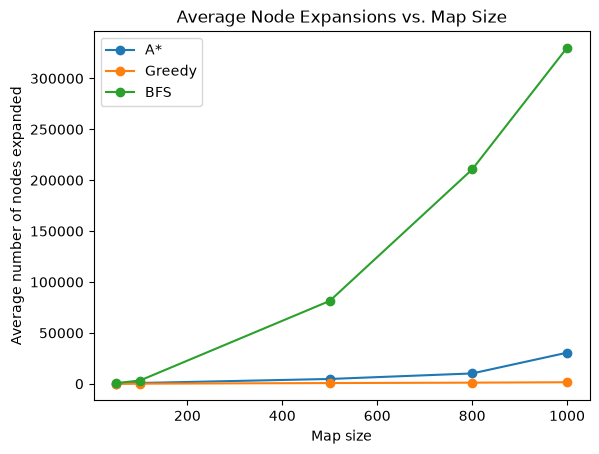

In [342]:
import matplotlib.pyplot as plt
import numpy as np

astar_node_y = []
greedy_node_y = []
bfs_node_y = []

astar_path_y = []
greedy_path_y = []
bfs_path_y = []

for size in SIZES:
    for algorithm, results in [
        ("astar", astar_node_y),
        ("greedy", greedy_node_y),
        ("bfs", bfs_node_y),
    ]:
        values = [
            node["expanded_node"]
            for node in node_y
            if node["algorithm"] == algorithm
            and node["map_size"] == size
        ]

        results.append(np.mean(values) if values else np.nan)

for size in SIZES:
    for algorithm, results2 in [
        ("astar", astar_path_y),
        ("greedy", greedy_path_y),
        ("bfs", bfs_path_y),
    ]:
        values = [
            node["path"]
            for node in path_y
            if node["algorithm"] == algorithm
            and node["map_size"] == size
        ]

        results2.append(np.mean(values) if values else np.nan)

print(greedy_node_y)
print(astar_node_y)

print(greedy_path_y)
print(astar_path_y)

plt.figure()
plt.title("Average Node Expansions vs. Map Size")
plt.xlabel("Map size")
plt.ylabel("Average number of nodes expanded")
plt.plot(SIZES, astar_node_y, marker="o", label="A*")
plt.plot(SIZES, greedy_node_y, marker="o", label="Greedy")
plt.plot(SIZES, bfs_node_y, marker="o", label="BFS")
plt.legend()
plt.show()

Text(0.5, 1.0, 'Ratio of greedy/optimal for map sizes')

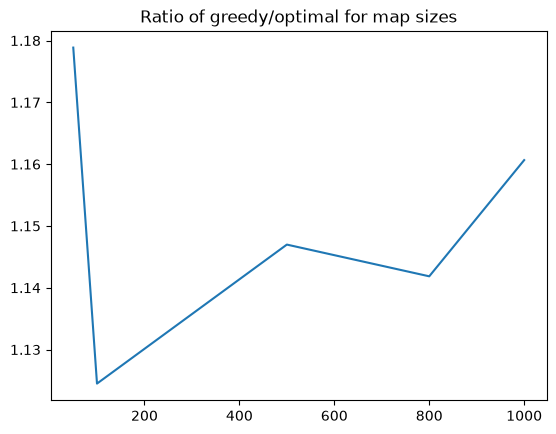

In [343]:
# Average Greedy/Optimal Path Cost Ratio vs. Map Size

ratio = []
for i, greedy in enumerate(greedy_path_y):
    ratio.append(greedy / astar_path_y[i])

plt.plot(SIZES, ratio)
plt.title("Ratio of greedy/optimal for map sizes")

In [344]:
...

Ellipsis

<!-- END QUESTION -->

**Make sure all of your code and plots for your experiment are above this cell**

#### **Exercise 1.5.2 (Written): Evaluate Scaling on Object Maps.** **(10 pts)**

Then, *after* your experiment answer the following two questions.

- What do these two plots demonstrate? How do Greedy / A* / and BFS compare across these dimensions for increasing map size?
- Did your predictions line up with your experiment? If not, explain why.

<!-- BEGIN QUESTION -->

- As the size of the map increases, the average node expansion also increases for each algorithm. BFS increased the most because it did not use the manhattan distance method so it has the same heuristic cost for each step. Greedy and A* search has similar rates of increase. Greedy search often expands fewer nodes because it follows the heuristic toward the goal, but it may take a longer or nonoptimal route.

- My prediction was that expanded nodes would increase with graph size, and the first plot supports it. Any irregularities or differences in the rate of growth may come from the particular map layouts, obstacle placement, and start/goal locations.

<!-- END QUESTION -->

### **1.7 Scaling Experiments: Maze Maps**

Instead of an empty floor with random objects scattered about, the `generate_maze` function generates a more traditional maze with long and twisting corridors. For maze maps, our initial state is still $(0,0)$, and the goal is moved to the bottom-right corner, $(n-1, n-1)$.

`generate_maze` takes a `braid` parameter - the fraction of dead ends opened into loops. `braid=0` gives a perfect maze with exactly one solution path (as in the preview below), while higher values create loops and multiple valid paths. For the experiments in this section we will use `braid=0.2`. 

Note that `generate_maze` rounds even sizes up to the next odd number. This won't majorly affect your final result.

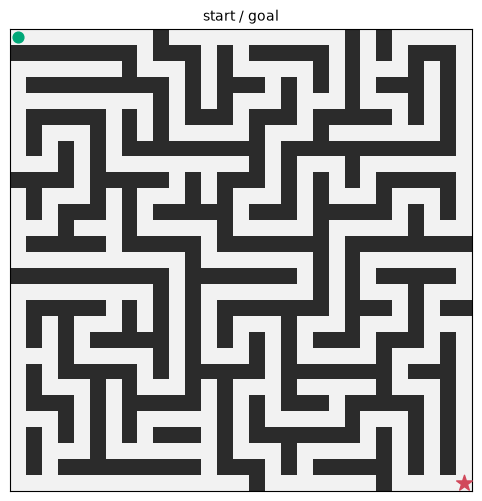

In [345]:
# Peek at the maze map
maze_map = generate_maze(29, seed=15, braid=0.2)
stepper(maze_map)

#### **Exercise 1.6.1 (Written): Predict Scaling on Maze Maps.** **(10 pts)**

**For this section, you will repeat the same analysis as you did for the object map, but for this different map type.**

Use the same seeds and map sizes. `DENSITY` does not apply here.

You must create the following two plots:
- Average Number of Node Expansions vs. Map Size per Algorithm for Maze
- Average Greedy/Optimal Path Cost Ratio vs. Map Size for Maze

Before performing the experiment, ask yourself the following questions:

- Do you think you'll get a different result for the number of expansions plot for the maze map compared to the obstacle map? If so why? If not, why not?
- Do you think you'll get a different result for the optimality ratio plot for the maze map compared to the obstacle map? If so why? If not, why not?

<!-- BEGIN QUESTION -->

- I think I will get a different result especially for BFS search since there aren't as many options for the graph and many times there is only one path. As such, the number of node expanded will not increase as quickly as before when the map size increases. I think A* will perform similar to greedy as before since there are less chances of running into a suboptimal path since there are less paths here. 

- I think the optimality ratio will be a lot closer this time just because greedy is less likely to run into sub-optimal paths here.

Now, write code to run the experiment on the *mazes*. I would encourage you to re-use the code you created for the previous question! Perhaps write a function or a class? Remember to generate the mazes with `braid=0.2`, and that even sizes round up to the next odd number.

In [346]:
SIZES = [50, 100, 500, 800, 1000]
RANDOM_SEEDS = [1, 2, 3, 4 , 5]
BRAID = 0.2

In [347]:
def change_even(num):
    if (num % 2 == 0):
        return num + 1

In [348]:
from search_viz import *
# Average Number of Node Expansions vs. Map Size per Algorithm
node_y = []
path_y = []
# maze_map = generate_maze(29, seed=15, braid=0.2)

for size in SIZES:
    for seed in RANDOM_SEEDS:
        map_grid = generate_maze(change_even(size), seed=seed, braid=0.2)

        astar_result = astar(
            map_grid,
            manhattan_distance,
            tie_break="h"
        )
        node_y.append({
            "algorithm": "astar",
            "map_size": size,
            "seed": seed,
            "expanded_node": astar_result.expanded,
        })
        path_y.append({
            "algorithm": "astar",
            "map_size": size,
            "seed": seed,
            "path": astar_result.path_cost,
        })

        greedy_result = greedy(
            map_grid, 
            manhattan_distance)
        node_y.append({
            "algorithm": "greedy",
            "map_size": size,
            "seed": seed,
            "expanded_node": greedy_result.expanded,
        })
        path_y.append({
            "algorithm": "greedy",
            "map_size": size,
            "seed": seed,
            "path": greedy_result.path_cost,
        })

        bfs_result = bfs(map_grid)
        node_y.append({
            "algorithm": "bfs",
            "map_size": size,
            "seed": seed,
            "expanded_node": bfs_result.expanded,
        })
        path_y.append({
            "algorithm": "bfs",
            "map_size": size,
            "seed": seed,
            "path": bfs_result.path_cost,
        })

print(f"Collected {len(node_y)} results")

Collected 75 results


[np.float64(576.4), np.float64(1407.8), np.float64(7783.0), np.float64(12565.4), np.float64(15181.6)]
[np.float64(761.0), np.float64(2985.0), np.float64(119303.4), np.float64(318740.6), np.float64(497552.2)]
[np.float64(320.8), np.float64(890.4), np.float64(3879.2), np.float64(6900.0), np.float64(7764.0)]
[np.float64(271.2), np.float64(805.6), np.float64(2879.2), np.float64(4606.4), np.float64(5832.8)]


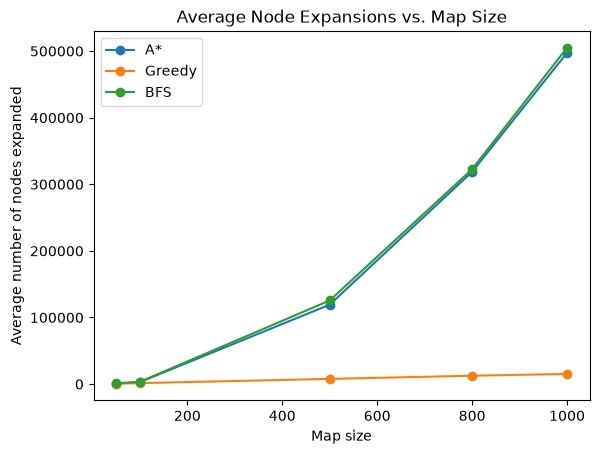

In [349]:
import matplotlib.pyplot as plt
import numpy as np

astar_node_y = []
greedy_node_y = []
bfs_node_y = []

astar_path_y = []
greedy_path_y = []
bfs_path_y = []

for size in SIZES:
    for algorithm, results in [
        ("astar", astar_node_y),
        ("greedy", greedy_node_y),
        ("bfs", bfs_node_y),
    ]:
        values = [
            node["expanded_node"]
            for node in node_y
            if node["algorithm"] == algorithm
            and node["map_size"] == size
        ]

        results.append(np.mean(values) if values else np.nan)

for size in SIZES:
    for algorithm, results2 in [
        ("astar", astar_path_y),
        ("greedy", greedy_path_y),
        ("bfs", bfs_path_y),
    ]:
        values = [
            node["path"]
            for node in path_y
            if node["algorithm"] == algorithm
            and node["map_size"] == size
        ]

        results2.append(np.mean(values) if values else np.nan)

print(greedy_node_y)
print(astar_node_y)

print(greedy_path_y)
print(astar_path_y)




plt.figure()
plt.title("Average Node Expansions vs. Map Size")
plt.xlabel("Map size")
plt.ylabel("Average number of nodes expanded")
plt.plot(SIZES, astar_node_y, marker="o", label="A*")
plt.plot(SIZES, greedy_node_y, marker="o", label="Greedy")
plt.plot(SIZES, bfs_node_y, marker="o", label="BFS")
plt.legend()
plt.show()

[np.float64(1.1828908554572273), np.float64(1.1052631578947367), np.float64(1.3473186996387885), np.float64(1.4979159430357765), np.float64(1.331093128514607)]


Text(0.5, 1.0, 'Ratio of greedy/optimal for map sizes')

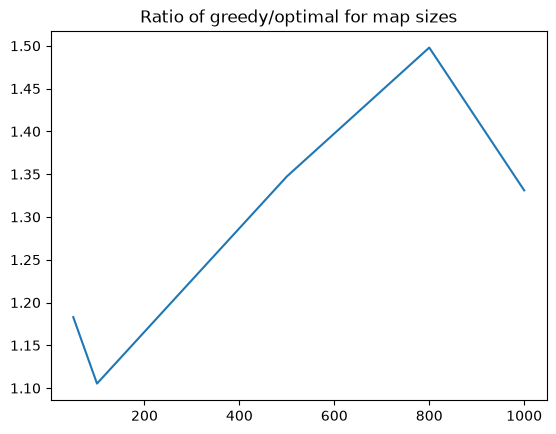

In [350]:
# Average Greedy/Optimal Path Cost Ratio vs. Map Size

ratio = []
for i, greedy in enumerate(greedy_path_y):
    ratio.append(greedy / bfs_path_y[i])

plt.plot(SIZES, ratio)
print(ratio)
plt.title("Ratio of greedy/optimal for map sizes")

<!-- END QUESTION -->

**Make sure all of your code and plots for your experiment are above this cell**.

#### **Exercise 1.6.2 (Written): Evaluate Scaling on Maze Maps.** **(10 pts)**

Answer the following questions *after* you've constructed your plots.

- What do these two plots demonstrate? How do Greedy / A* / and BFS compare across these dimensions for increasing map size with the maze map type?
- Did your predictions line up with your experiment? If so, what is the underlying mechanism that led you to making your correct prediction? If not, what is the underlying mechanism that led to the difference?

<!-- BEGIN QUESTION -->

- The first plot demonstrated that the most optimal search algorithm for this is BFS search because it has the lowest node expanded as the graph size increases. A* and Greedy are roughly the same rate of increase and both are not very efficient. The second plot shows 

- I think my prediction was off since the expanded nodes for BFS is way fewer than the other two algorithms sine BFS is exploring all of the paths at once without thinking of the heuristic costs. The second plot shows that greedy is similar to optimal at the start but as the map gets bigger the difference starts to show. This is because as the map gets bigger there are more path with dead-ends so it has to go back more but for BFS or the optimal algorithm in this case, it is exploring all paths so it will jump to the next avaiable path which decreases the path cost as the graph size increases.

<!-- END QUESTION -->

## **2. Graphs for Real-(ish) Data**

For this part of the assignment, you'll be using the [NetworkX](https://networkx.org/) library to analyze path networks in a more authentic scenario. In NetworkX, you can easily create graphs that have nodes and edges.

I would recommend looking at the [tutorial](https://networkx.org/documentation/stable/tutorial.html)!

### **2.1 Intro to NetworkX**

Let's build a small graph step by step.

In [351]:
import networkx as nx

# We can define our graph as follows
G = nx.Graph()

# We can add nodes
G.add_node("A")
G.add_node("B")

# We can also add multiple nodes at once
G.add_nodes_from(["C", "D", "E"])

# And we can print the nodes in our graph
G.nodes

NodeView(('A', 'B', 'C', 'D', 'E'))

Now that we defined our graph nodes, we can add edges between them.

In [352]:
# We can add an edge like this...
G.add_edge("A","B")

# Or add edges from a list...
G.add_edges_from(
    [
    ("B","C"),
    ("B", "D")
    ]
)

# And we can view all the edges we added!
G.edges

EdgeView([('A', 'B'), ('B', 'C'), ('B', 'D')])

We can draw the graph as well.

Note: You may notice that if you call `nx.draw()` multiple times, you will get different looking images. Finding the best way to automatically draw an arbitrary graph in a way that captures its structure (especially with lots of nodes) is a surprisingly difficult problem and an active research area in data visualization (See [this article](https://en.wikipedia.org/wiki/Graph_drawing) for more).

Rest assured, the underlying structure and edge connections are the same.

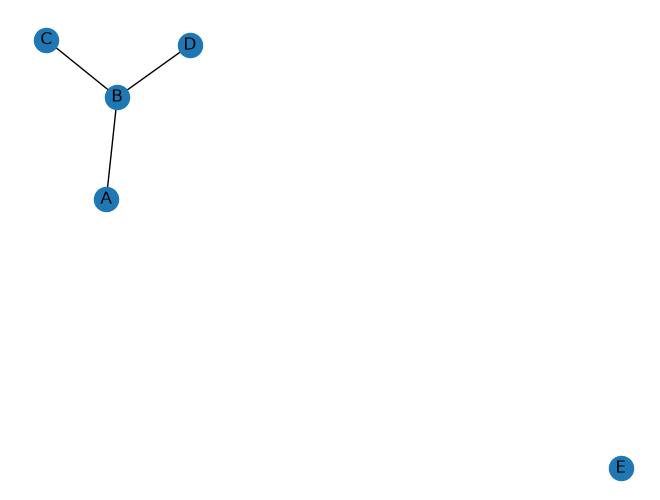

In [353]:
nx.draw(G, with_labels=True)

Finally, we can edit our graph to remove nodes and edges.

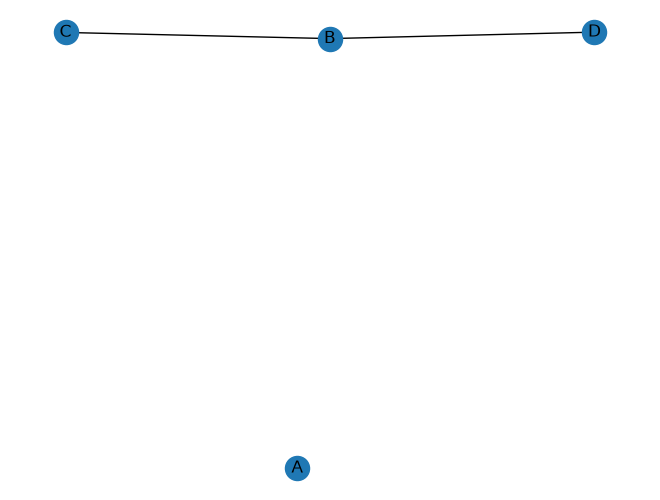

In [354]:
G.remove_node("E")
G.remove_edge("B", "A")

nx.draw(G, with_labels=True)

One of the most powerful features of NetworkX is that nodes can be anything, and nodes and edges can carry an arbitrary amount of attributes.

In [355]:
friend_graph = nx.Graph()

# We add nodes to represent the people "Max", "Sarah", and "Thomas"
# And our nodes can contain *multiple* attributes
friends = [
    ("Max", {"year": "Freshman"}),
    ("Sarah", {"year": "Sophomore"}),
    ("Thomas", {"year": "Graduate Student", "program": "PhD"})

]

# Add all of our nodes...
friend_graph.add_nodes_from(friends)

print(friend_graph.nodes)
print(friend_graph.nodes["Max"])
print(friend_graph.nodes["Thomas"]['program'])

['Max', 'Sarah', 'Thomas']
{'year': 'Freshman'}
PhD


In [356]:
# It is a similar process for edges: each edge carries its own
# dictionary of attributes.
friend_edges = [
    ("Max", "Sarah", {"friend_level": 23}),
    ("Sarah", "Thomas", {"friend_level": -10, "rivalry_level": 10})
]

friend_graph.add_edges_from(friend_edges)

print(friend_graph.get_edge_data("Max", "Sarah"))
print(friend_graph.get_edge_data("Sarah", "Thomas"))

{'friend_level': 23}
{'friend_level': -10, 'rivalry_level': 10}


### **2.2 The Campus Graph**

**Archdale University** is a small college that has both the pleasure and displeasure of sitting at the top of a hill overlooking Emerald City. The pleasure comes from the fact that the views are amazing -- the displeasure comes from the fact that getting around campus and its myriad of elevation changes is quite the challenge.

You're part of the team creating the app *ArchWalk*, which helps students get around campus -- the bigger named apps are more focused on driving directions around the city, so a smaller local solution was warranted.

After some extensive data entry by surveying students, you have a pretty good map of campus that you could represent as a graph. Nodes are common locations on campus (such as residence halls, lecture halls, and points of interest). Edges are official pathways between nodes. Edges can have multiple attributes -- not only do they carry the actual distance of the path, but also a *grade*, a number representing how steep the path is.

The code for loading the campus graph is provided for you.

In [357]:
import json
import networkx as nx

# Load up our campus graph
def load_graph(graph_name):
    with open(graph_name) as f:
        data = json.load(f)

    G = nx.Graph()
    for n in data["nodes"]:
        G.add_node(n["id"], **{k: v for k, v in n.items() if k != "id"})
    for e in data["edges"]:
        G.add_edge(e["u"], e["v"], **{k: v for k, v in e.items() if k not in ("u", "v")})

    return G

G = load_graph("campus_graph.json")

In [358]:
# We can print all the nodes in our graph
print(G.nodes)

['HILL_HALL', 'SUMMIT_HALL', 'BEACON_HALL', 'UPPER_QUAD', 'NORTH_DINING', 'REC_CENTER', 'BELL_TOWER', 'SWITCH_A', 'SWITCH_B', 'SWITCH_C', 'STAIR_TOP', 'STAIR_BOTTOM', 'CHAPEL', 'MAIN_GATE', 'CENTRAL_GREEN', 'SCI_CENTER', 'ENG_BUILDING', 'LECTURE_HALL', 'LIBRARY', 'SOUTH_DINING', 'STUDENT_CTR', 'ART_STUDIO', 'HEALTH_CTR', 'BUS_STOP', 'PARKING_S']


In [359]:
# As well as the individual properties of each node
print(G.nodes["HILL_HALL"])

{'name': 'Hillcrest Hall', 'category': 'residence', 'x_m': 120, 'y_m': 520, 'elevation_m': 41.0}


Nodes have the following properties:

- `name` - The name of the node
- `category` - The type of building or location the node is
    - This can be one of: `residence`, `dining`, `academic`, `social`, `services`, `green`, `parking`, `transit`, `gateway`, `athletics`, `landmark`, `path`
- `x_m` - The x coordinate of the node on the map (in meters)
- `y_m` - the y coordinate of the node on the map (in meters)
- `elevation_m` - The elevation of the location (in meters)

In [360]:
# Get our edges...
print(G.edges)

[('HILL_HALL', 'SUMMIT_HALL'), ('HILL_HALL', 'UPPER_QUAD'), ('HILL_HALL', 'NORTH_DINING'), ('SUMMIT_HALL', 'BEACON_HALL'), ('SUMMIT_HALL', 'UPPER_QUAD'), ('BEACON_HALL', 'UPPER_QUAD'), ('BEACON_HALL', 'REC_CENTER'), ('UPPER_QUAD', 'NORTH_DINING'), ('UPPER_QUAD', 'REC_CENTER'), ('UPPER_QUAD', 'BELL_TOWER'), ('NORTH_DINING', 'SWITCH_A'), ('REC_CENTER', 'BELL_TOWER'), ('REC_CENTER', 'CHAPEL'), ('BELL_TOWER', 'SWITCH_A'), ('BELL_TOWER', 'STAIR_TOP'), ('SWITCH_A', 'SWITCH_B'), ('SWITCH_B', 'SWITCH_C'), ('SWITCH_C', 'HEALTH_CTR'), ('SWITCH_C', 'SCI_CENTER'), ('STAIR_TOP', 'STAIR_BOTTOM'), ('STAIR_TOP', 'CHAPEL'), ('STAIR_BOTTOM', 'CENTRAL_GREEN'), ('STAIR_BOTTOM', 'LECTURE_HALL'), ('CHAPEL', 'ART_STUDIO'), ('MAIN_GATE', 'LIBRARY'), ('MAIN_GATE', 'SOUTH_DINING'), ('MAIN_GATE', 'STUDENT_CTR'), ('MAIN_GATE', 'BUS_STOP'), ('MAIN_GATE', 'PARKING_S'), ('CENTRAL_GREEN', 'LIBRARY'), ('CENTRAL_GREEN', 'LECTURE_HALL'), ('CENTRAL_GREEN', 'SCI_CENTER'), ('SCI_CENTER', 'ENG_BUILDING'), ('SCI_CENTER', 'HE

In [361]:
print(G.get_edge_data("HILL_HALL", "SUMMIT_HALL"))

{'path_type': 'walkway', 'distance_m': 88.6, 'grade_pct': 1.13, 'accessible': True}


Edges have the following properties:

- `path_type` - The type of path this is.
    - This can be one of {"walkway", "stairs", "indoor", "path"}
- `distance_m` - The total length of the path.
- `grade_pct` - The grade of the walkway in percentage points (i.e. how steep the path is).
- `accessible` - Whether the path is usable by everyone. In this data, paths steeper than a grade of 8.33% are marked not accessible (shown as dashed red edges on the map below).

We've also given you some code to visualize the graph (Note: I used Claude Opus to help generate this visualization code).

In [362]:
import matplotlib.pyplot as plt


def draw_map(G):
    pos = {n: (G.nodes[n]["x_m"], G.nodes[n]["y_m"]) for n in G}

    fig, ax = plt.subplots(figsize=(11, 12))

    elev = [G.nodes[n]["elevation_m"] for n in G]
    nodes = nx.draw_networkx_nodes(
        G, pos, node_color=elev, cmap="terrain", node_size=320,
        edgecolors="black", linewidths=0.6, ax=ax,
    )
    plt.colorbar(nodes, ax=ax, label="elevation (m)", shrink=0.6)

    acc = [(u, v) for u, v, a in G.edges(data="accessible") if a]
    inacc = [(u, v) for u, v, a in G.edges(data="accessible") if not a]
    nx.draw_networkx_edges(G, pos, edgelist=acc, edge_color="#444", width=1.6, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=inacc, edge_color="crimson",
                        width=2.4, style="dashed", ax=ax)

    nx.draw_networkx_labels(
        G, pos, labels={n: G.nodes[n]["name"] for n in G},
        font_size=7, verticalalignment="bottom", ax=ax,
    )
    ax.set_aspect("equal")
    ax.set_title("Campus — dashed red = grade > 8.33% (not accessible)")
    ax.axis("off")
    plt.show()

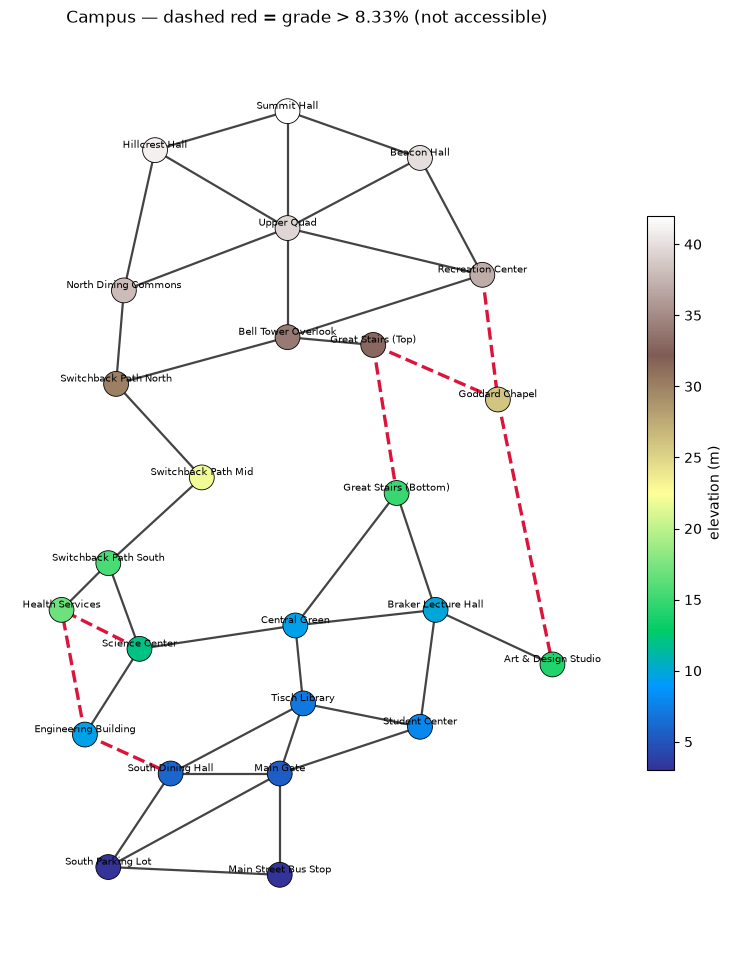

In [363]:
draw_map(G)

### **2.3 Making Personalized Maps**

A grade of 5% or greater means that the pathway is legally a *ramp*, which triggers a host of required compliancy factors such as handrails and edge protections. Ramps have a maximum grade of 8.33%; anything higher is not ADA compliant even if it is a smooth surface. One general strategy for personalized routes and maps is to preprocess or edit a *copy* of the original graph beforehand (such as adding and removing edges) and then running routing algorithms on it.

#### **Exercise 2.1: `remove_high_grade_edges`**

Write the function `remove_high_grade_edges(graph, grade_threshold)` which takes `graph` as input and a `grade_threshold`, and creates a *copy* of the graph with all edges of `grade_threshold` or higher removed.

In [364]:
def remove_high_grade_edges(graph, grade_threshold):
    new_graph = graph.copy()
    for u, v in new_graph.edges():
        if new_graph.get_edge_data(u, v).get("grade_pct") >= grade_threshold:
            new_graph.remove_edge(u, v)
    return new_graph

In [365]:
grader.check("q_remove_high_grade_edges")

q_remove_high_grade_edges results: All test cases passed!

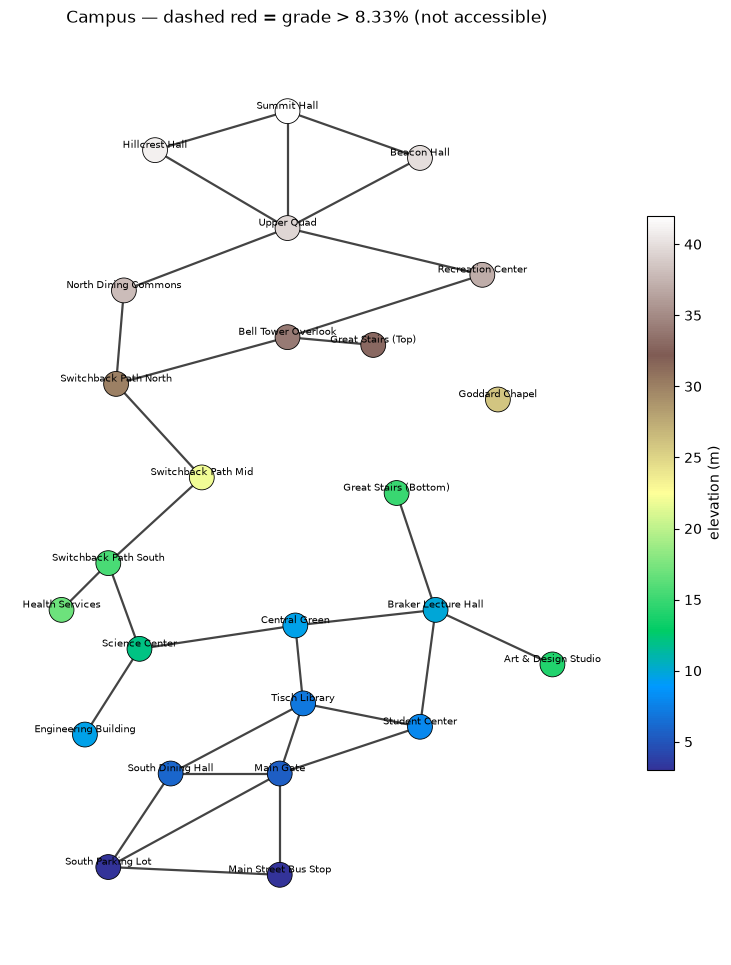

In [366]:
# We can view the connection graph of the map with different grades present
g_copy = remove_high_grade_edges(G, 5)
draw_map(g_copy)

### **2.4 Finding Total Travel Distance**

Say a student has a list of stops that they want to go to in a specific order (e.g. Residence Hall -> Lecture Hall -> Dining Hall -> Lecture Hall). A value that would be helpful to know is the total travel distance that it would take to visit all of those locations in that specific sequence -- assuming that the shortest path is taken for each leg of the journey.

Before writing the function, let's see how NetworkX computes a single shortest path.

In [367]:
# We have to pass in a "weight" parameter
# Otherwise networkX treats the graph as unweighted
# And tries to find the shortest path of just edge count (BFS)


path_nodes = nx.shortest_path(G, 
                               source="HILL_HALL", 
                               target="SCI_CENTER", 
                               weight='distance_m'
                               )

path_nodes


['HILL_HALL',
 'UPPER_QUAD',
 'BELL_TOWER',
 'STAIR_TOP',
 'STAIR_BOTTOM',
 'CENTRAL_GREEN',
 'SCI_CENTER']

In [368]:
path_len = nx.shortest_path_length(G, 
                                   source="HILL_HALL", 
                                   target="SCI_CENTER", 
                                   weight='distance_m')

# Get the cost of the above path
print(path_len)

579.9


#### **Exercise 2.2: `get_total_travel_distance`**

Complete the function `get_total_travel_distance(graph, locations)`, which gets the total travel distance of sequentially visiting each location in the `locations` list, assuming the shortest path is being taken between locations. If it is impossible to visit all of the locations, it should return `None`.

In [369]:
def get_total_travel_distance(graph, locations):
    total_travel_distance = 0
    # if locations.size() == 0 or locations.size() == 1:
    #     return 0
    for i in range(len(locations) - 1):
        try: 
            total_travel_distance += nx.shortest_path_length(
                graph,
                source=locations[i],
                target=locations[i+1],
                weight="distance_m"
                )
        except (nx.NetworkXNoPath, nx.NodeNotFound):
            return None

    return total_travel_distance

In [370]:
grader.check("q_total_travel_distance")

q_total_travel_distance results: All test cases passed!

### **2.5 Data Analysis**

A recent student survey came in where students were asked to provide lists of a common schedule of their day and what locations they visited. In addition, students who indicated accessibility needs were also asked what the maximum path grade is that they are comfortable with. You're given two files:

- `no_accessibility_needs.csv`
- `accessibility_needs.csv`

For students without accessibility needs, students with accessibility needs, and the group as a whole, compute the mean, median, and maximum of the travel distances.

#### **Exercise 2.3: Analyze the Route Data**

Load the two route files, compute the total travel distance for each proposed route (using `get_total_travel_distance`), and summarize the mean, median, and maximum travel distances for each group and for everyone combined. We've given you some code that loads the CSV files for you.

Fill out the function `summarize_times` that returns the mean, median, and max value for a given list of routes.

In [371]:
import csv
import statistics

def load_routes(filename, with_grade=False):
    """Parse each row: optional leading max grade, then the route stops."""
    routes = []
    with open(filename, newline="") as f:
        reader = csv.reader(f)
        next(reader, None)  # header
        for row in reader:
            if row:
                cells = [loc.strip() for loc in row]
                routes.append((float(cells[0]), cells[1:]) if with_grade else cells)
    return routes

no_accessability_need_routes = load_routes("no_accessibility_needs.csv")
accessibility_needs_routes = load_routes("accessibility_needs.csv", with_grade=True)

In [372]:
def summarize_times(times):
    if not times:
        return None, None, None

    mean = statistics.mean(times)
    median = statistics.median(times)
    maximum = max(times)

    return mean, median, maximum

In [373]:
no_accessibility_distances = [
    get_total_travel_distance(G, route)
    for route in no_accessability_need_routes
]

accessibility_distances = [
    get_total_travel_distance(G, stops)
    for max_grade, stops in accessibility_needs_routes
]

# Exclude routes with no path, for which get_total_travel_distance returns None
no_accessibility_distances = [
    distance for distance in no_accessibility_distances
    if distance is not None
]
accessibility_distances = [
    distance for distance in accessibility_distances
    if distance is not None
]

all_distances = no_accessibility_distances + accessibility_distances

print(no_accessability_need_routes)
print(accessibility_needs_routes)

print("Routes without accessibility needs:",
      summarize_times(no_accessibility_distances))
print("Routes with accessibility needs:",
      summarize_times(accessibility_distances))
print("All routes:",
      summarize_times(all_distances))

[['HILL_HALL', 'LECTURE_HALL', 'NORTH_DINING', 'LECTURE_HALL', 'HILL_HALL'], ['SUMMIT_HALL', 'SCI_CENTER', 'SOUTH_DINING', 'SCI_CENTER', 'SUMMIT_HALL'], ['HILL_HALL', 'ART_STUDIO', 'STUDENT_CTR', 'SOUTH_DINING', 'HILL_HALL'], ['UPPER_QUAD', 'REC_CENTER', 'STUDENT_CTR', 'HEALTH_CTR', 'UPPER_QUAD'], ['BEACON_HALL', 'LIBRARY', 'STUDENT_CTR', 'BEACON_HALL'], ['STAIR_TOP', 'STAIR_BOTTOM', 'LECTURE_HALL', 'CENTRAL_GREEN', 'STAIR_BOTTOM', 'STAIR_TOP'], ['HILL_HALL', 'CHAPEL', 'LECTURE_HALL', 'HILL_HALL'], ['NORTH_DINING', 'HILL_HALL', 'SUMMIT_HALL', 'BEACON_HALL', 'REC_CENTER', 'NORTH_DINING'], ['BUS_STOP', 'MAIN_GATE', 'STUDENT_CTR', 'LECTURE_HALL', 'LIBRARY', 'BUS_STOP'], ['SOUTH_DINING', 'ENG_BUILDING', 'SCI_CENTER', 'HEALTH_CTR', 'SOUTH_DINING']]
[(5.0, ['HILL_HALL', 'LECTURE_HALL', 'NORTH_DINING', 'LECTURE_HALL', 'HILL_HALL']), (5.0, ['SUMMIT_HALL', 'SCI_CENTER', 'SOUTH_DINING', 'SCI_CENTER', 'SUMMIT_HALL']), (6.0, ['HILL_HALL', 'ART_STUDIO', 'STUDENT_CTR', 'SOUTH_DINING', 'HILL_HALL']),

In [374]:
grader.check("q_data_analysis")

q_data_analysis results: All test cases passed!

#### **Exercise 2.4 (Written): Your Interpretation** **(10 pts)**

Comment on the results by answering the following questions:

- What do you notice based on your analysis? 
- Inspect some of routes across the populations and comment on the things you see.
- Imagine the situation where someone just calculated the shortest routes on campus for everyone without splitting it up via accessability concerns. What might they conclude, and what would they miss? How does this tie into the theme of this course on how the definition of your problem defines your solutions?

<!-- BEGIN QUESTION -->

- routes with accessibility needs seem to have a higher average and median travel distane than routes without accessibility needs. Specifically, routes without accessibility has 1030 as the mean but for those with accessibility it has 1350. Both of the group have the same max of 1954.8. This suggests that road with accessibility needs often need to cover more distance but the shared max shows that there is at least one route that shares the same distance between the two. 

- Looking at individual paths, we can see that the reason these accessibility need routes have higher distances is because it often needs detours that have accessibility paths in order to reach certain destination. For instance, from Hill Hall to lecture hall the non-accessibility route is through chapel but the accessibility route has to go through upper-quad, rec center and etc in order to get to the same destination. This makes the route distance a lot longer.

- If someone calculated “the shortest route on campus” without considering accessibility, they might conclude that campus travel is generally shorter than it is for people who need accessible paths. That solution would optimize distance while leaving out whether a path can actually be used by everyone. This connects to the course theme: how we define a problem determines what counts as a good solution. If accessibility is not part of the problem definition, the result may be shortest on paper but unsuitable for some people.

<!-- END QUESTION -->

## **Collaboration Statement** **(10 points)**

You are required to complete the following collaboration statement.

<!-- BEGIN QUESTION -->

- If you completed the lab in a group - list all your group members here, including yourself. **If you worked individually, you must state *"I worked by myself."***
    - I worked by myself.
- You must list the names of any others you got help from when completing this assignment (including TAs), and in what way you worked with them (discussed ideas, debugged math). **If you did not collaborate at all, you must state *"I did not collaborate with anyone else."***
    - I did not collaborate with anyone else.
- If you found any resources online helpful, you must link them and describe how you found them helpful (or not helpful). **If you did not use any resources online, you must state *"I did not use any resources online."***
    - I used nx website for finding network graph methods including how to remove and iterate.
- If you used any AI assistive technologies, you must describe how you used them and how you found them helpful (or not helpful). **If you did not use any AI assistive technologies, you must state *"I did not use any AI assistive technologies."***
    - Some AI suggestions came up during google search that I looked at including iterating over loop and plotting a plt line graph.
- If you have any questions or comments about the material, or there was a topic or question you are confused on -- please make a note of it here! **If you do not have any questions or comments, you must state *"I do not have any questions or comments about the assignment."***
    - I do not have any questions or comments about the assignment.
- Estimate how long this assignment took you in hours. **You must give an estimate**.
    - This assignment took me about 5 hours to complete.

<!-- END QUESTION -->



## Submission

Make sure you have run all cells in your notebook in order before running the cell below, so that all images/graphs appear in the output. The cell below will generate a zip file for you to submit. **Please save before exporting!**

Run every cell from top to bottom and SAVE before exporting. Then submit
the generated .zip to the HW3 autograder assignment on Gradescope.


In [376]:
# Save your notebook first, then run this cell to export your submission.
grader.export(pdf=False, run_tests=True)

Running your submission against local test cases...


Your submission received the following results when run against available test cases:

    q_manhattan_distance results: All test cases passed!

    q_remove_high_grade_edges results: All test cases passed!

    q_total_travel_distance results: All test cases passed!

    q_data_analysis results: All test cases passed!
